# Sesión 2 · Taller: transformaciones y PCA
**Misión 9–11 nov 2026 · Lunes 9 · segunda mitad (~30 min)**

Completa las celdas marcadas con `# TODO`: reemplaza cada `...` por tu código. Las celdas **✅ verificación** te dicen si vas bien. Todo se vio en la demo.

| Ejercicio | Tema | Min |
|---|---|---|
| 1 | Escalar variables de `tips` | 8 |
| 2 | Variables categóricas | 7 |
| 3 | Discretizar | 5 |
| 4 | PCA en `penguins` | 10 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
tips = sns.load_dataset("tips")
penguins = sns.load_dataset("penguins").dropna().reset_index(drop=True)
tips_num = ["total_bill", "tip", "size"]
peng_num = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## Ejercicio 1 · Escalar variables de `tips`
Aplica `MinMaxScaler` y `StandardScaler` a las columnas `tips_num`. Guarda cada resultado como DataFrame con los mismos nombres de columna y compara con `describe()`.

In [5]:
X = tips[tips_num]
X_minmax = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=tips_num)  # TODO: pd.DataFrame(MinMaxScaler().fit_transform(X), columns=tips_num)
X_std = pd.DataFrame(StandardScaler().fit_transform(X), columns=tips_num)     # TODO: lo mismo con StandardScaler

print("MinMax:"); display(X_minmax.describe().loc[["min", "max"]].round(2))
print("Standard:"); display(X_std.describe().loc[["mean", "std"]].round(2))

MinMax:


,total_bill,tip,size
min,0.0,0.0,0.0
max,1.0,1.0,1.0


Standard:


,total_bill,tip,size
mean,-0.0,0.0,-0.0
std,1.0,1.0,1.0


In [6]:
# ✅ verificación
assert np.allclose(X_minmax.min(), 0) and np.allclose(X_minmax.max(), 1), "MinMax debe quedar entre 0 y 1"
assert np.allclose(X_std.mean(), 0, atol=1e-9), "Standard debe tener media 0"
print("Ejercicio 1 ✔")

Ejercicio 1 ✔


**Pregunta:** después de escalar con MinMax, ¿qué significa que una cuenta tenga `total_bill = 1`?

*Tu respuesta:* …

## Ejercicio 2 · Variables categóricas
a) One-Hot de la columna `time` (Lunch / Dinner).
b) Codificación ordinal de `day` respetando el orden Thur < Fri < Sat < Sun.

In [7]:
ohe = OneHotEncoder(sparse_output=False)
time_ohe = pd.DataFrame(ohe.fit_transform(tips[["time"]]), columns=ohe.get_feature_names_out())   # TODO: pd.DataFrame(ohe.fit_transform(tips[["time"]]), columns=ohe.get_feature_names_out())
display(pd.concat([tips[["time"]], time_ohe], axis=1).head())

ordinal = OrdinalEncoder(categories=[["Thur", "Fri", "Sat", "Sun"]])        # TODO: OrdinalEncoder(categories=[["Thur", "Fri", "Sat", "Sun"]])
tips["day_num"] = ordinal.fit_transform(tips[["day"]]).ravel() # TODO: ordinal.fit_transform(tips[["day"]]).ravel()
tips[["day", "day_num"]].drop_duplicates().sort_values("day_num")

,time,time_Dinner,time_Lunch
0,Dinner,1.0,0.0
1,Dinner,1.0,0.0
2,Dinner,1.0,0.0
3,Dinner,1.0,0.0
4,Dinner,1.0,0.0


,day,day_num
77,Thur,0.0
90,Fri,1.0
19,Sat,2.0
0,Sun,3.0


In [8]:
# ✅ verificación
assert time_ohe.shape[1] == 2
assert tips.loc[tips.day == "Sun", "day_num"].iloc[0] == 3
print("Ejercicio 2 ✔")

Ejercicio 2 ✔


**Pregunta:** ¿por qué NO usarías la codificación ordinal para la columna `sex`?

*Tu respuesta:* …

## Ejercicio 3 · Discretizar
Divide la propina (`tip`) en 3 grupos con la misma cantidad de cuentas: `"baja"`, `"media"`, `"alta"` (usa `pd.qcut`). Muestra cuántas cuentas hay en cada grupo y su mínimo y máximo.

In [10]:
tips["nivel_propina"] = pd.qcut(tips["tip"], q=3, labels=["baja", "media", "alta"])  # TODO: pd.qcut(tips["tip"], q=3, labels=[...])
tips.groupby("nivel_propina", observed=True)["tip"].agg(["count", "min", "max"])

,count,min,max
nivel_propina,,,
baja,83,1.00,2.03
media,80,2.05,3.25
alta,81,3.27,10.00


## Ejercicio 4 · PCA en `penguins`
1. Escala `peng_num` con `StandardScaler`.
2. Aplica `PCA(n_components=2)` y muestra el % de información que conserva cada componente.
3. Grafica PC1 vs PC2 coloreando por `species`.

% de información: [68.6 19.5]


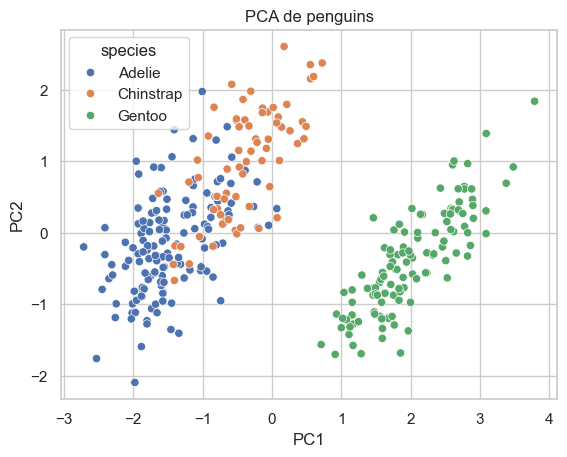

In [12]:
X_esc = StandardScaler().fit_transform(penguins[peng_num]) # TODO: StandardScaler().fit_transform(penguins[peng_num])
pca = PCA(n_components=2)   # TODO: PCA(n_components=2)
Z = pca.fit_transform(X_esc)      # TODO: pca.fit_transform(X_esc)
print("% de información:", (pca.explained_variance_ratio_ * 100).round(1))

ax = sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=penguins["species"])
ax.set(xlabel="PC1", ylabel="PC2", title="PCA de penguins")
plt.show()

In [13]:
# ✅ verificación
assert Z.shape == (len(penguins), 2)
print(f"Ejercicio 4 ✔ · PC1 + PC2 conservan {pca.explained_variance_ratio_.sum():.0%}")

Ejercicio 4 ✔ · PC1 + PC2 conservan 88%


**Preguntas:**
1. ¿Qué % de la información conservan las 2 componentes juntas?
2. ¿Qué especie se separa más de las otras?

*Tus respuestas:* …

## ⭐ Reto (si te sobra tiempo)
Repite el ejercicio 4 **sin escalar** (usa `penguins[peng_num]` directamente). ¿Qué cambia en el gráfico? ¿Por qué?

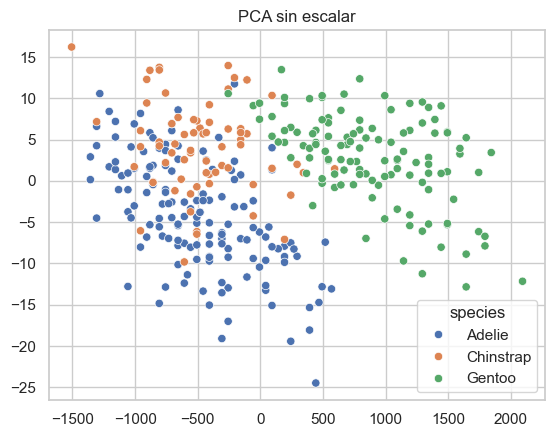

In [15]:
Z_sin = PCA(n_components=2).fit_transform(penguins[peng_num])  # TODO
sns.scatterplot(x=Z_sin[:, 0], y=Z_sin[:, 1], hue=penguins["species"]).set(title="PCA sin escalar")
plt.show()